# AI4GSD Demo
------------------------------------------
## Drone Videos
------------------------------------------
#### Table of contents
#### 0. Installing requried packages (please restart the kernel after installation)
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI, drone flight data, or manual measurements
#### 5. Obtaining segmentation of anthropogenic objects
#### 6. Obtaining grain size data
#### 7. Applying quality control

##### *** Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors

------------------------------------------
### 0. Installing requried packages (please restart the kernel after installation)

In [1]:
#!pip install --user natsort
#!pip install --user ismember

### 1. Importing required packages

In [2]:
import sys
from pathlib import Path
CWD = Path.cwd()
sys.path.insert(0, str(CWD.parent))
import AI4GSD

### 2. Defining working directory

In [3]:
AI4GSD.pcinfo()
foldername = '20241130_YC_DroneVideoFieldTest'                             # Parent folder where you save photos/videos.
WorkDir = CWD.parent
PhotoDir = str(WorkDir / 'Demo_Data' / foldername)                         # AI4GSD use string path.  

Machine name: PNNL-2MQ6330S2G
Operating system: Windows 11 Pro (build 26200)
Architecture: AMD64
Processor: Intel(R) Core(TM) Ultra 7 366H
Reported CPU frequency: 2.00 GHz


### 3. Extracting or copying your videos/photos to desired folder

In [4]:
AI4GSD.getPhotos(PhotoDir,nframe=2000, overwrite=False)                    # Use once.

Video photo output folder: D:\Github\AI4GSD\Demo_Data\20241130_YC_DroneVideoFieldTest
Extracting DJI_0113.MOV every 2000 frames.
DJI_0113.MOV: get frame 1 from 2000/5759 in 12.65 s (34.73%)
DJI_0113.MOV: get frame 2 from 4000/5759 in 12.04 s (69.46%)

Computation done, elapsed time 26.71 seconds.




### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [5]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.OverWriteAll = True                                                     # Overwrite everything if True.
PP.OverWriteScaleFile = True
PP.OverWriteScaleRows = True
PP.ScaleSource = 'log'                                                     # Use drone log option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ImageSizeFactor = 1                                                     # Do you need to user a larger image size for inference?
PP.ConfidenceThresholdUser = 0.85                                          # Minimum confidence threshold.
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
scales =  AI4GSD.metadata(PP)

Generating scale file for: 20241130_YC_DroneVideoFieldTest
Reading DJI flight logs from files
1/2: photo 1/2, DJI_0113_2000.png, scale log, res 0.59 mm/px, status -1, (50.00%), 3.28 s
2/2: photo 2/2, DJI_0113_4000.png, scale log, res 0.73 mm/px, status -1, (100.00%), 0.75 s
Total time: 4.15 s, time per photo 2.07 s
-----------------------------------------------------------------



### 5. Obtaining segmentation of anthropogenic objects

In [6]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250906'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = True
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.ImageSizeFactor=1
PP.SegmentationClassName = ['board','redbag','people']                     # What object class need to track.
AI4GSD.background(PP)

-----------------------------------------------------------------
Folder name: 20241130_YC_DroneVideoFieldTest
output name: segments
Model name: YOLO11m.640.20250906 from local for anthro
Model layer: 125, model parmeter: 22.37M, submodule number: 445
IOU: 0.45, user confidence: 0.35
Number of photos: 2, number of exluded photos 0
20241130_YC_DroneVideoFieldTest: 1/2, DJI_0113_2000.png, no objects (50.00%)
20241130_YC_DroneVideoFieldTest: 2/2, DJI_0113_4000.png, no objects (100.00%)
Total time: 8.43 s, time per photo 4.21 s
-----------------------------------------------------------------



### 6. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Folder name: 20241130_YC_DroneVideoFieldTest
Output folder: 20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 2, number of exluded photos 0
1/2: DJI_0113_2000.png, resolution 0.59 mm/px (50.00%), 0.00 s
Detected 66 rocks, diagonal and count based D10, D50, D60, and D84 are: 6.69, 14.51, 16.56, and 28.64 cm
Detected 66 rocks, diagonal and area  based D10, D50, D60, and D84 are: 14.07, 32.19, 38.54, and 48.53 cm


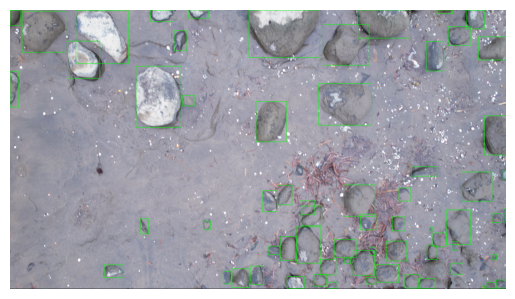

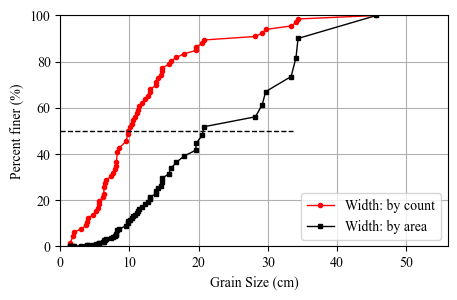

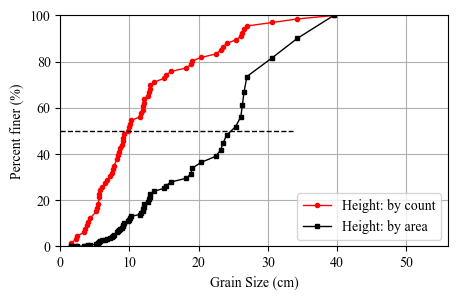

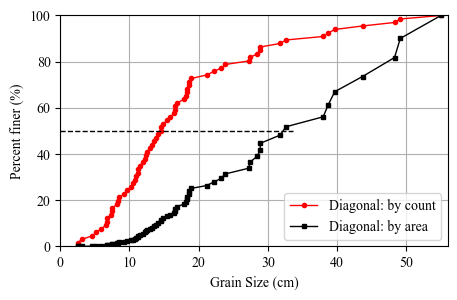

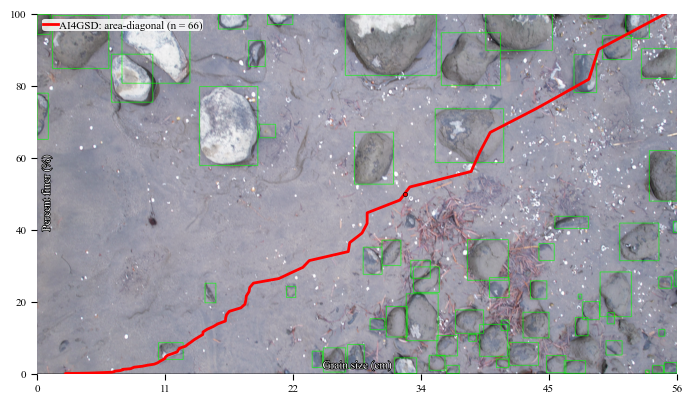

2/2: DJI_0113_4000.png, resolution 0.73 mm/px (100.00%), 13.20 s
Detected 3056 rocks, diagonal and count based D10, D50, D60, and D84 are: 3.36, 4.54, 4.86, and 6.26 cm
Detected 3056 rocks, diagonal and area  based D10, D50, D60, and D84 are: 3.86, 5.86, 6.69, and 11.54 cm


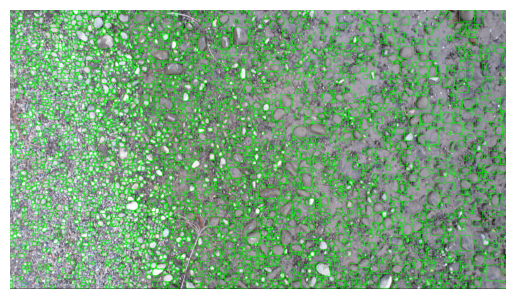

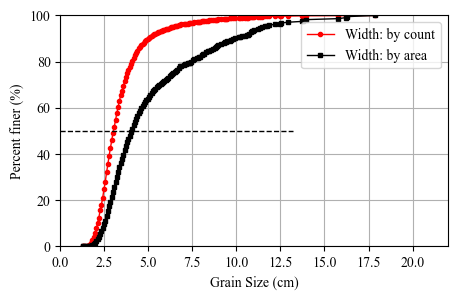

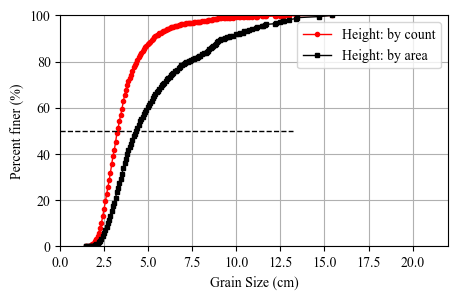

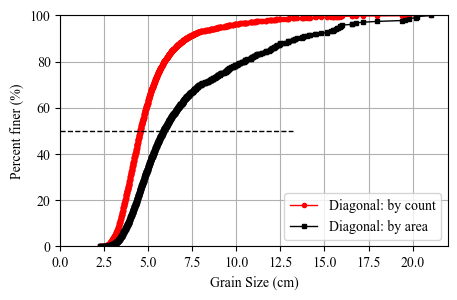

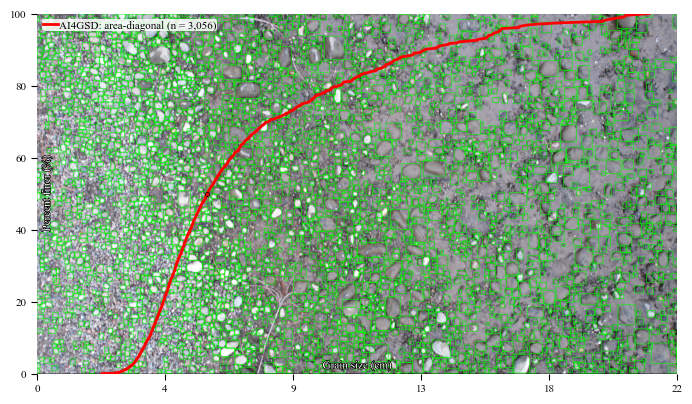

Output folder summary data to: D:\Github\AI4GSD\Demo_Data\20241130_YC_DroneVideoFieldTest\grains_predicts\20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35\Statistics_V3_20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35.csv
Total number of grains: 3122, number of grains per photo: 1561.00
Total time: 28.42 s, time per photo 14.21 s

Output all summary data to: D:\Github\AI4GSD\Demo_Data\20241130_YC_DroneVideoFieldTest\Statistics_V3_20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35.csv
Total execution time: 28.44 s


In [7]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.OverWriteAll = True
PP.YOLOSave = False
PP.SaveOverlayLabel = True
PP.PrintOnScreen = True 
PP.OverlayFontSize = 4
PP.OverlayLegendFontSize = 4
PP.OverlayGSDTickLineWidth = 4
gsd = AI4GSD.Photo2GSD(PP)

### 7. Applying quality control

In [8]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20241130_YC_DroneVideoFieldTest:
1/1: DJI_0113.MOV, time 240.2 s, area 14.8 m2, valid area 9.0 m2 (60.8%), frame 2, valid frame 1 (50.0%)
1/1: ***, grain number 3122, number per image 1561.0; efficiency 0.1 m2/s, 13.0 grains/s
